# Case Study 3 — Does One Shared "Foundation" Representation Help Four Payment Decisions? Out-of-Time, Fixed-Alert-Budget and Calibration Evaluation

**Priority:** ★★ Good to have · **Reference:** Case Study 3 — *Razorpay Vulcan: one foundation model for routing, fraud, COD risk and checkout ranking* (`indian_fintech_data_science_case_studies.md`)
**Audience:** CTO / Head of Data Science, Payments product, Risk operations, Checkout product
**Data:** ⚠️ **SYNTHETIC** (D-3b-01). Gateway logs are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs03_foundation_model_evaluation.ipynb`

## 0. Executive Summary for Business

*(Synthetic data with a transparent, CPU-sized stand-in for Razorpay's Vulcan. Written after the analysis.)*

- **The question:** should one shared "foundation" representation of payments, learned from unlabelled data, replace or feed four separate models (routing, fraud, COD return risk, checkout method ordering)?
- **The answer is "it depends on the task", and only an honest test shows which.** The representation clearly works as a representation: it recovers the hidden shopper segment 92% of the time (vs 24% by chance) and predicts a field it never saw (the bank) at 1.8× chance.
- **Where it helped:**
  - **Checkout ordering:** shoppers seeing their chosen method first rose from 41.1% to **44.9% (+9% relative, McNemar p < 1e-100)**, and +15% vs "always show UPI". The gain holds even with only 5% of the labels.
  - **COD return (RTO) risk:** AUC +0.017 (Holm p = 0.015), but that is worth little in ₹ (top-10% precision 42.6% → 43.6%).
- **Where it did not help:**
  - **Routing:** −0.1 pp. Routing success depends on bank × gateway × time, not on who the shopper is. A plain task model already lifts SR **+5.1 pp** over a random split, close to the true-best "oracle" (+5.2 pp).
  - **Fraud:** it made things **worse**: AUC 0.74 → 0.66, and at a fixed 0.5% alert budget recall fell from 28% to 20% (borderline, McNemar p = 0.06; significant at a 1% budget, p = 0.007). With only ~550 known frauds to learn from, 32 extra dimensions let the model chase noise, and the new fraud ring's devices were unseen at pre-training.
- **Evaluation lessons that transfer to any model:**
  - A **random split overstates fraud AUC** (0.77 vs 0.72–0.74 out-of-time).
  - Only 29% of frauds are labelled within 2 weeks.
  - Class-balanced training keeps AUC but makes RTO probabilities **22 points too high** until isotonic recalibration.
  - With ~120 test frauds, fraud comparisons have only ≈ 60% power.
- **₹ (per 1 crore payments/month, illustrative):**
  - Model-based routing ≈ **+₹51 crore GMV/month** vs random gateway assignment.
  - The shared representation on checkout ≈ +₹0.4 crore (if "shown first" lifts completion 1 pp).
  - On fraud ≈ −₹0.5 crore. **Do not use it there.**
- **I recommend:** adopt the shared representation **per task, only where it passes an out-of-time, business-metric test**: checkout now, and RTO optionally. Keep task-specific models for routing and fraud. Re-test fraud with ≥ 8 weeks of matured labels and a lower-capacity head.

## 1. The Problem in Simple English

A payment gateway makes four different predictions on every payment:
1. **Routing:** which bank gateway will make this payment succeed?
2. **Fraud:** is this payment fraudulent?
3. **COD risk:** if it is cash-on-delivery, will the parcel be refused and come back (RTO)?
4. **Checkout ordering:** which payment method will this shopper choose, so we show it first?

Usually each has its own team, data pipeline and model. Razorpay's idea ("Vulcan") is to first learn **one general-purpose description of a payment** from billions of *unlabelled* payments: who pays, on which device, at which merchant, from where. Then each task adds a small model on top. This is the "foundation model" idea from AI, applied to payments.

Leaders need to know: **does a shared representation actually beat task-specific models, for which tasks, and how do we test that honestly?** Fraud labels arrive weeks late, so a careless test can flatter a model. This notebook builds a small, transparent version of the idea and tests it the way the Razorpay blog describes: **out-of-time**, at a **fixed fraud-alert budget**, with **calibration checked separately from ranking**, and by **slice**.

## 2. Reference from the Case File

### (a) What Razorpay did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | Separate models for "millisecond routing", "fraud patterns that move across merchants", "COD parcel rejection (RTO)" and "ordering payment methods at checkout" |
| Data | "3 trillion data points across 4 billion payments"; "3,000 signals per transaction"; identifiers removed; categorical fields → **hashed tokens**; each payment = **set of fields** |
| Approach | Self-supervised **masked-field prediction** pre-training → **Set Transformer** backbone → task heads (routing: recent-context encoder + fusion + calibration) |
| Evaluation | "**Out-of-time, per payment flow**"; "Train on the past… test on later traffic… inspect the slices"; **calibration evaluated separately from ranking**; fraud models compared at **fixed alert volumes**. Formal hypothesis tests: ND |
| Impact (Inc42, launch press) | "**8–10%** improvement in payment success rates"; "**8X** increase in international card frauds detected"; "**5X** rise in fraudulent/disputed transactions identified" "without an increase in alerts"; "**40%** more shoppers seeing preferred UPI app at checkout" |

**Sources:** Razorpay blog, 10 Sep 2026 — https://razorpay.com/blog/vulcan-how-razorpay-built-a-foundation-model-for-payment-decisions · Inc42, 18 Aug 2026 — https://inc42.com/buzz/razorpay-launches-ai-foundation-model-vulcan-to-expedite-digital-payments/

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | ≈ 342k payments over 12 weeks from 40k shoppers (plus fraud-ring identities), 1,500 merchants, 600 pincodes, 20 banks, 3 gateways. A hidden shopper **segment** drives who buys where, with which method and how risky their COD parcels are. A fraud ring **changes targets** mid-period. |
| Representation | A **transparent, CPU-sized stand-in** for Vulcan: payments as sets of **hashed field tokens** → IDF weighting → **truncated SVD** (a linear self-supervised embedding learned without labels from field co-occurrence). Each payment's vector is the **sum of its field vectors**, which is permutation-invariant like a Set Transformer's pooled output (D-3b-03). |
| Heads | The same gradient-boosting head per task, **with vs without** the shared representation, so the comparison isolates its value |
| Statistics added | Linear probes with binomial tests; DeLong paired AUC tests (Holm); recall at a fixed alert budget with McNemar and bootstrap CIs; random-split vs out-of-time and "as-of" vs "hindsight" labels; Brier, ECE, calibration-in-the-large and slope, isotonic recalibration; per-flow slices (BH); a label-efficiency curve; off-policy (IPW) routing evaluation; power |

### (c) How the industry uses this

Foundation models for transactions are a 2024–26 trend: Stripe's payments foundation model (fraud and authorisation), Visa and Mastercard transaction models, and Nubank's "nuFormer" (transaction-sequence transformers for credit). In India, Razorpay Vulcan, and token or sequence embeddings at PhonePe and Paytm for fraud and personalisation. Regardless of model size, **the evaluation discipline in this notebook (out-of-time, fixed alert budget, calibration, slices) is the industry standard** for deciding whether a new model replaces an old one.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we invest in one shared payment representation instead of separate task models, and for which decisions? |
| Analytical | Does adding the shared representation to each task's model improve **out-of-time** performance on the metric the business uses (routing SR, fraud caught at a fixed alert budget, RTO ranking, checkout top-1 accuracy), and is it still **calibrated**? |

**Hypotheses (one per task; Holm across tasks):**
- **H1 (fraud):** H0: recall at a 0.5% alert budget is equal with and without the shared representation (McNemar on the same frauds). AUC compared with DeLong.
- **H2 (RTO):** H0: AUC(with) = AUC(without) on out-of-time COD orders (DeLong).
- **H3 (routing):** H0: the expected SR of the model's gateway choice is equal with and without (paired bootstrap on true success probabilities; IPW off-policy estimate as the "real-world" check).
- **H4 (checkout):** H0: top-1 accuracy (the predicted method is the one chosen) is equal (McNemar).
- **H5 (representation quality):** H0: a linear probe on the embedding predicts the hidden segment and a masked field (issuer) no better than the majority class (exact binomial test).

**Design:** pre-train on weeks 1–8 (no labels); train heads on weeks 1–8; recalibrate on weeks 9–10; **test on weeks 11–12**. Fraud labels are used **as known on the deployment date (day 70)**.
**Decision rule:** adopt the shared representation for a task only if it improves that task's business metric (Holm p < 0.05) **and** remains calibrated. Keep the task-specific model otherwise.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction import FeatureHasher
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public multi-task payment logs (routing + fraud + COD + method choice) | **None.** Gateway logs are confidential (PCI-DSS, RBI data localisation). Public fraud sets (e.g., IEEE-CIS, ULB credit-card) are Kaggle-hosted, single-task, and anonymised PCA features with no entity tokens. |
| **Decision** | Synthetic payments with shared hidden structure and four labelled tasks (D-3b-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs03.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 3 (Razorpay Vulcan-style shared payment representation, 4 tasks)
=====================================================================================================
THIS DATA IS SYNTHETIC. Payment-gateway logs are confidential.

One payment = a set of fields (customer, device, merchant, pincode, method, issuer, gateway, amount, time).
A hidden customer SEGMENT (K = 6) drives which merchants people buy from, where they live, which
methods they prefer and how risky their COD parcels are. Co-occurrence of fields therefore carries
information that a self-supervised representation can pick up without labels.

Four labelled tasks share the same payments:
  1. route_success - online payment succeeded on the (randomly logged) gateway G1/G2/G3
  2. is_fraud      - chargeback / confirmed fraud; label arrives 5-60 days later (label_date)
  3. rto           - COD parcel returned to origin (COD orders only)
  4. method        - payment method the shopper chose (checkout ordering)
Fraud has a ring that changes targets mid-period (concept drift) - why out-of-time tests matter.

Calibration anchors (reference file, Case Study 3): fraud labels "confirmed weeks later";
evaluation "out-of-time, per payment flow"; "fixed alert volumes"; calibration evaluated separately.
Rates are our assumptions (decision.md D-3-02). Hidden truth columns start with "_".

Output: data/cs03/payments.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit, softmax

SEED = 42
START = pd.Timestamp("2026-01-05"); DAYS = 84
K = 6
METHODS = ["upi", "card", "netbanking", "wallet", "cod"]
CATS = ["fashion", "electronics", "grocery", "home", "food", "travel", "digital_goods", "education"]
COD_OK = {"fashion", "electronics", "grocery", "home"}
BANKS = [f"B{i:02d}" for i in range(20)]
GWS = ["G1", "G2", "G3"]


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # ---------- entities ----------
    seg_p = np.array([0.24, 0.20, 0.18, 0.15, 0.13, 0.10])
    n_cust, n_merch, n_pin = 40_000, 1_500, 600
    pin_seg = rng.integers(0, K, n_pin)
    pin_risk = np.array([-0.8, -0.4, 0.0, 0.3, 0.6, 0.9])[pin_seg] + rng.normal(0, 0.5, n_pin)
    m_seg = rng.integers(0, K, n_merch)
    m_cat = rng.choice(CATS, n_merch, p=[0.20, 0.14, 0.14, 0.10, 0.14, 0.08, 0.12, 0.08])
    m_pop = rng.gamma(0.8, 1.0, n_merch)
    c_seg = rng.choice(K, n_cust, p=seg_p)
    c_pin = np.array([rng.choice(np.flatnonzero(pin_seg == s)) for s in c_seg])
    seg_meth = np.array([[1.6, 0.4, -0.4, 0.2, -0.6], [1.2, 0.9, 0.2, -0.3, -1.2], [1.0, -0.2, -0.6, 0.4, 0.6],
                         [0.6, -0.6, -0.8, 0.0, 1.3], [0.4, 1.4, 0.6, -0.4, -1.0], [1.4, -0.4, -1.0, 0.9, 0.3]])
    c_meth = seg_meth[c_seg] + rng.normal(0, 0.8, (n_cust, 5))
    seg_bank = rng.dirichlet(np.ones(len(BANKS)) * 0.6, K)
    c_bank = np.array([rng.choice(len(BANKS), p=seg_bank[s]) for s in c_seg])
    c_rto = rng.normal(0, 0.7, n_cust)
    c_dev = np.array([f"D{i:06d}" for i in range(n_cust)])
    second = rng.random(n_cust) < 0.12
    c_dev2 = np.where(second, [f"D{i + 500000:06d}" for i in range(n_cust)], c_dev)
    n_pay = rng.poisson(rng.gamma(1.5, 5.0, n_cust)) + 1
    # ---------- legit payments ----------
    ci = np.repeat(np.arange(n_cust), n_pay); N = len(ci)
    seg = c_seg[ci]
    own = rng.random(N) < 0.70
    m_by_seg = [np.flatnonzero(m_seg == s) for s in range(K)]
    w_by_seg = [m_pop[m] / m_pop[m].sum() for m in m_by_seg]
    merch = np.empty(N, int)
    for s in range(K):
        idx = np.flatnonzero(own & (seg == s)); merch[idx] = rng.choice(m_by_seg[s], len(idx), p=w_by_seg[s])
    idx = np.flatnonzero(~own); merch[idx] = rng.choice(n_merch, len(idx), p=m_pop / m_pop.sum())
    cat = m_cat[merch]
    amt = np.round(np.exp(rng.normal(np.log(650), 0.9, N) + 0.6 * np.isin(cat, ["electronics", "travel"]) - 0.4 * (cat == "food")), 0)
    ts = START + pd.to_timedelta(rng.uniform(0, DAYS * 86400, N), unit="s")
    hour = pd.DatetimeIndex(ts).hour.to_numpy()
    lg = c_meth[ci] + np.c_[np.zeros(N), 0.35 * np.log(amt / 650), np.zeros(N), -0.3 * np.log(amt / 650), np.zeros(N)]
    lg[~np.isin(cat, list(COD_OK)), 4] = -np.inf
    P = softmax(lg, axis=1); u = rng.random(N)[:, None]
    meth = np.array(METHODS)[(P.cumsum(1) < u).sum(1).clip(0, 4)]
    dev = np.where(rng.random(N) < 0.85, c_dev[ci], c_dev2[ci])
    pay = pd.DataFrame({"ts": ts, "customer_id": [f"C{i:06d}" for i in ci], "device_id": dev, "merchant_id": [f"M{m:05d}" for m in merch],
                        "merchant_cat": cat, "pincode": [f"PIN{p:04d}" for p in c_pin[ci]], "method": meth, "amount_inr": amt,
                        "_segment": seg, "_cidx": ci, "_ring": 0})
    pay["issuer"] = np.where(pay.method.isin(["card", "netbanking", "upi"]), np.array(BANKS)[c_bank[ci]], "none")
    # ---------- fraud ring (A: weeks 1-8 digital goods/electronics; B: weeks 7-12 travel/new merchants) ----------
    rings = []
    for name, d0, d1, cats_, ndev in (("A", 0, 56, ["digital_goods", "electronics"], 30), ("B", 42, 84, ["travel", "digital_goods"], 30)):
        targets = rng.choice(np.flatnonzero(np.isin(m_cat, cats_)), 25, replace=False)
        for d in range(ndev):
            dv = f"RD{name}{d:03d}"; t0 = rng.uniform(d0, d1 - 7) * 86400
            for c in range(rng.integers(4, 12)):
                cid = f"CR{name}{d:03d}{c:02d}"; pin = rng.integers(n_pin)
                for _ in range(rng.integers(1, 3)):
                    rings.append((START + pd.Timedelta(seconds=t0 + rng.uniform(0, 7 * 86400)), cid, dv, f"M{rng.choice(targets):05d}", pin,
                                  rng.choice(["card", "upi"], p=[0.75, 0.25]), float(np.round(np.exp(rng.normal(np.log(3500), 0.5)))), name))
    r = pd.DataFrame(rings, columns=["ts", "customer_id", "device_id", "merchant_id", "pin", "method", "amount_inr", "_ring"])
    r["merchant_cat"] = m_cat[r.merchant_id.str[1:].astype(int)]; r["pincode"] = [f"PIN{p:04d}" for p in r.pin]
    r["issuer"] = rng.choice(BANKS, len(r)); r["_segment"] = -1; r["_cidx"] = -1
    pay = pd.concat([pay, r.drop(columns="pin")], ignore_index=True)
    N = len(pay); hour = pay.ts.dt.hour.to_numpy(); is_ring = pay._ring.astype(str).isin(["A", "B"]).to_numpy()
    pay["card_network"] = np.where(pay.method == "card", rng.choice(["Visa", "Mastercard", "RuPay"], N, p=[0.5, 0.33, 0.17]), "none")
    intl = (pay.method == "card") & (rng.random(N) < np.where(is_ring, 0.6, 0.02))
    pay["bin_country"] = np.where(pay.method == "card", np.where(intl, "international", "domestic"), "none")
    # ---------- task 2: fraud ----------
    night = (hour <= 4).astype(float)
    z_f = (-7.6 + 0.9 * np.log(pay.amount_inr / 650).clip(0) + 1.2 * night + 1.5 * intl + 0.8 * (pay.merchant_cat == "digital_goods")
           + 0.5 * pay.device_id.str.startswith("D5").astype(float))                       # second (newer) device
    p_f = np.where(is_ring, 0.75, expit(z_f))
    pay["_p_fraud"] = p_f; pay["is_fraud"] = (rng.random(N) < p_f).astype(int)
    pay["label_date"] = pd.NaT
    fr = pay.is_fraud == 1
    pay.loc[fr, "label_date"] = pay.loc[fr, "ts"] + pd.to_timedelta(np.exp(rng.normal(np.log(21), 0.6, fr.sum())).clip(3, 75), unit="D")
    # ---------- task 1: route success (online methods; gateway randomly logged) ----------
    online = pay.method != "cod"
    gw = rng.choice(GWS, N); pay["gateway"] = np.where(online, gw, "none")
    bank_i = pay.issuer.map({b: i for i, b in enumerate(BANKS)}).fillna(-1).astype(int).to_numpy()
    gx = rng.normal(0, 0.55, (len(BANKS) + 1, 3)); gx[-1] = 0
    base = pay.method.map({"upi": 1.7, "card": 1.9, "netbanking": 1.6, "wallet": 2.6, "cod": 0}).to_numpy()
    peak = ((hour >= 19) & (hour <= 22)).astype(float)
    netw = pay.card_network.map({"Visa": 0.0, "Mastercard": 0.1, "RuPay": -0.2, "none": 0}).to_numpy()
    seg_sr = np.r_[np.array([0.2, 0.1, 0.0, -0.2, 0.1, -0.1]), 0.0][pay._segment.to_numpy()]
    p_g = np.zeros((N, 3))
    for g in range(3):
        p_g[:, g] = expit(base + gx[bank_i, g] + [0.0, 0.15, -0.1][g] - [0.0, 0.5, 0.1][g] * peak + (g == 2) * 0.4 * (netw < 0) + seg_sr - 0.3 * intl)
        pay[f"_p_{GWS[g]}"] = np.where(online, p_g[:, g], np.nan)
    gi = pd.Series(gw).map({g: i for i, g in enumerate(GWS)}).to_numpy()
    pay["route_success"] = np.where(online, (rng.random(N) < p_g[np.arange(N), gi]).astype(float), np.nan)
    # ---------- task 3: RTO on COD ----------
    pin_i = pay.pincode.str[3:].astype(int).to_numpy()
    cidx = pay._cidx.to_numpy()
    z_r = (-1.5 + pin_risk[pin_i] + np.where(cidx >= 0, c_rto[cidx.clip(0)], 0.8) + 0.45 * (pay.merchant_cat == "fashion")
           + 0.3 * np.log(pay.amount_inr / 650))
    pay["_p_rto"] = np.where(pay.method == "cod", expit(z_r), np.nan)
    pay["rto"] = np.where(pay.method == "cod", (rng.random(N) < expit(z_r)).astype(float), np.nan)
    # ---------- tidy + data-quality defects ----------
    pay = pay.sort_values("ts").reset_index(drop=True)
    pay.insert(0, "payment_id", [f"PAY{i:08d}" for i in range(1, len(pay) + 1)])
    pay.loc[pay.sample(frac=0.015, random_state=seed).index, "pincode"] = np.nan          # missing pincode (digital orders)
    pay.loc[pay.sample(n=400, random_state=seed + 1).index, "amount_inr"] = 0              # zero-amount test pings
    pay = pd.concat([pay, pay.sample(n=900, random_state=seed + 2)], ignore_index=True)   # duplicate webhook rows
    pay["_ring"] = pay["_ring"].astype(str)
    return pay


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs03"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs03", "payments.csv.gz"), index=False)
    print(len(d), "rows"); dd = d.drop_duplicates("payment_id")
    print(dd.method.value_counts(normalize=True).round(3).to_dict())
    print("fraud", dd.is_fraud.mean().round(5), dd.is_fraud.sum(), "| by ring", dd.groupby("_ring").is_fraud.sum().to_dict())
    print("route SR", dd.route_success.mean().round(3), "| RTO", dd.rto.mean().round(3), dd.rto.notna().sum())

Overwriting data/generate_cs03.py


In [3]:
os.makedirs("data/cs03", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs03 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs03/payments.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.payment_id.nunique():,} unique payments")
raw.drop(columns=[c for c in raw.columns if c.startswith("_")]).sample(3, random_state=SEED).T

342,894 rows | 341,994 unique payments


,65080,246667,75786
payment_id,PAY00065081,PAY00246668,PAY00075787
ts,2026-01-20 23:44:22.687096966,2026-03-06 14:18:27.532510119,2026-01-23 15:05:46.925868903
customer_id,C018590,C033865,C022925
device_id,D018590,D033865,D022925
merchant_id,M00484,M01233,M00615
merchant_cat,food,education,fashion
pincode,PIN0361,PIN0519,PIN0182
method,wallet,card,card
amount_inr,"3,331.0000","1,241.0000",304.0000
issuer,none,B03,B17


| Parameter | Value | Basis |
|---|---|---|
| Entities | 40k shoppers in 6 hidden segments; 1,500 merchants (8 categories); 600 pincodes; 20 banks; gateways G1–G3 | Our assumption |
| Shared structure | 70% of a shopper's purchases are at merchants of their own segment; pincode, bank, method preference and COD risk depend on segment | Our assumption: the reason a shared representation *can* help |
| Routing | Success ≈ 87%; bank × gateway effects, G2 weak at 7–10 pm, RuPay better on G3; gateway **randomly logged** (exploration) | Our assumption |
| Fraud | ≈ 0.3%: individual fraud (night, high value, international, new device) + **fraud ring A** (weeks 1–8) and **ring B** (weeks 7–12, new devices, new merchants); label delay 3–75 days (median 21) | **Documented:** fraud "confirmed weeks later", patterns "move across merchants" |
| COD / RTO | ≈ 10% COD; RTO ≈ 28% (pincode risk + shopper habit + fashion) | Typical Indian e-commerce RTO 20–30% |
| DQ issues | 900 duplicate webhook rows; 400 ₹0 test pings; 1.5% missing pincode | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("payment_id, ts", "Payment identity and time"), ("customer_id, device_id", "Hashed shopper and device tokens"),
    ("merchant_id, merchant_cat", "Merchant token and category"), ("pincode", "Delivery / billing pincode token (1.5% missing)"),
    ("method", "upi / card / netbanking / wallet / cod (target of the checkout task)"), ("issuer, card_network, bin_country", "Bank, card scheme, domestic/international ('none' if not applicable)"),
    ("amount_inr", "Payment value"), ("gateway", "Gateway the payment was (randomly) routed to; 'none' for COD"),
    ("route_success", "Task 1: online payment succeeded"), ("is_fraud, label_date", "Task 2: confirmed fraud and the date the label became known"),
    ("rto", "Task 3: COD parcel returned (COD only)"), ("_segment, _ring, _p_*", "HIDDEN truth (never used as features): segment, ring, true probabilities"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs03/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"payment_id, ts",Payment identity and time
1,"customer_id, device_id",Hashed shopper and device tokens
2,"merchant_id, merchant_cat",Merchant token and category
3,pincode,Delivery / billing pincode token (1.5% missing)
4,method,upi / card / netbanking / wallet / cod (target...
5,"issuer, card_network, bin_country","Bank, card scheme, domestic/international ('no..."
6,amount_inr,Payment value
7,gateway,Gateway the payment was (randomly) routed to; ...
8,route_success,Task 1: online payment succeeded
9,"is_fraud, label_date",Task 2: confirmed fraud and the date the label...


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs03/payments.csv.gz", parse_dates=["ts", "label_date"], keep_default_na=False, na_values=[""])
checks = {"duplicate payment_id (webhook replays)": int(df.payment_id.duplicated().sum()), "amount = ₹0 (test pings)": int((df.amount_inr == 0).sum()),
          "pincode missing": int(df.pincode.isna().sum()), "fraud without label_date": int(((df.is_fraud == 1) & df.label_date.isna()).sum()),
          "label_date before payment": int((df.label_date < df.ts).sum()), "rto on non-COD": int((df.rto.notna() & (df.method != "cod")).sum()),
          "route_success on COD": int((df.route_success.notna() & (df.method == "cod")).sum())}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("payment_id"); df = df[df.amount_inr > 0].sort_values("ts").reset_index(drop=True)
df["pincode"] = df.pincode.fillna("UNK")
df["day"] = (df.ts - gen.START).dt.total_seconds() / 86400
df["week"] = (df.day // 7).astype(int) + 1
df["hour"] = df.ts.dt.hour; df["log_amt"] = np.log(df.amount_inr)
# real-time ("as-of") features: computed only from earlier payments
first_pair = ~df.duplicated(["device_id", "customer_id"])
df["dev_ncust"] = first_pair.astype(int).groupby(df.device_id).cumsum()
df["cust_nprior"] = df.groupby("customer_id").cumcount()
df["cust_last_method"] = df.groupby("customer_id").method.shift().fillna("none")
iscod = (df.method == "cod").astype(int); r_ = df.rto.fillna(0)
df["cust_prior_cod"] = iscod.groupby(df.customer_id).cumsum() - iscod
df["cust_prior_rto"] = r_.groupby(df.customer_id).cumsum() - r_
df["merch_nprior"] = df.groupby("merchant_id").cumcount()
TR, CAL, TE = (df.day < 56).values, ((df.day >= 56) & (df.day < 70)).values, (df.day >= 70).values
DEPLOY = gen.START + pd.Timedelta(days=70)
df["fraud_asof"] = ((df.is_fraud == 1) & (df.label_date <= DEPLOY)).astype(int)
print(f"\nClean: {len(df):,} payments | train (wk 1–8) {TR.sum():,} · calibration (wk 9–10) {CAL.sum():,} · test (wk 11–12) {TE.sum():,}")

duplicate payment_id (webhook replays)     900
amount = ₹0 (test pings)                   401
pincode missing                           5139
fraud without label_date                     0
label_date before payment                    0
rto on non-COD                               0
route_success on COD                         0



Clean: 341,594 payments | train (wk 1–8) 227,693 · calibration (wk 9–10) 57,060 · test (wk 11–12) 56,841


**Observation:** we removed **900 duplicate webhook rows** and **401 ₹0 test pings** (not real payments: they would dilute fraud and success rates). 5,139 payments (1.5%) have no pincode (digital goods); they get an explicit "UNK" token rather than being dropped. Label logic is clean: every fraud has a label date after the payment, RTO exists only for COD, and routing outcomes only for online payments. Real-time features are computed **strictly from earlier payments** (e.g., distinct shoppers on a device so far), so no future information leaks in. Split: 227,693 training, 57,060 calibration and **56,841 out-of-time test** payments.

## 6. Exploratory Data Analysis

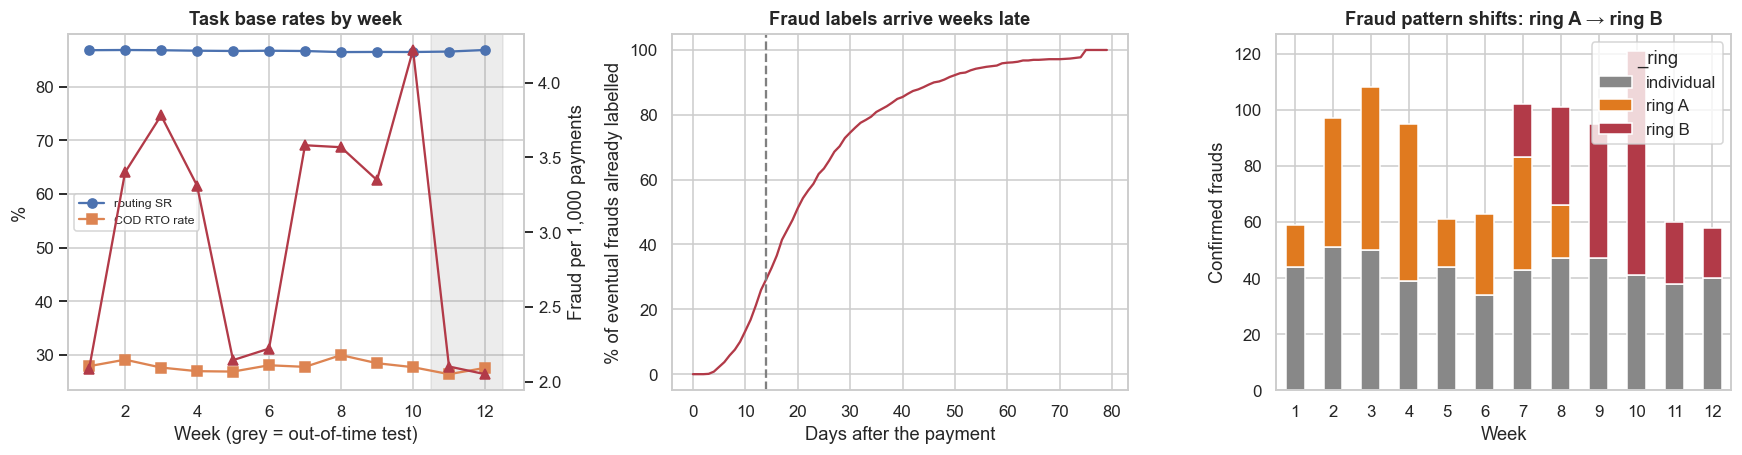

Fraud labelled within 14 days: 29%; within 30 days: 75%; median delay 20 days


Training-window frauds known on the deployment date: 547 of 686 (80%)


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
wk = df.groupby("week").agg(route=("route_success", "mean"), rto=("rto", "mean"), fraud=("is_fraud", "mean"))
axes[0].plot(wk.index, wk.route * 100, "o-", label="routing SR"); axes[0].plot(wk.index, wk.rto * 100, "s-", label="COD RTO rate")
ax2 = axes[0].twinx(); ax2.plot(wk.index, wk.fraud * 1000, "^-", color="#b23a48", label="fraud per 1,000"); ax2.set_ylabel("Fraud per 1,000 payments"); ax2.grid(False)
axes[0].axvspan(10.5, 12.5, color="grey", alpha=0.15); axes[0].set_xlabel("Week (grey = out-of-time test)"); axes[0].set_ylabel("%"); axes[0].set_title("Task base rates by week"); axes[0].legend(loc="center left", fontsize=8)
fr = df[df.is_fraud == 1]; delay = (fr.label_date - fr.ts).dt.days
xs = np.arange(0, 80); axes[1].plot(xs, [(delay <= x).mean() * 100 for x in xs], color="#b23a48")
axes[1].axvline(14, ls="--", color="grey"); axes[1].set_xlabel("Days after the payment"); axes[1].set_ylabel("% of eventual frauds already labelled")
axes[1].set_title("Fraud labels arrive weeks late")
mix = pd.crosstab(df.week, df._ring.replace({"0": "individual", "A": "ring A", "B": "ring B"}), values=df.is_fraud, aggfunc="sum")
mix.plot(kind="bar", stacked=True, ax=axes[2], color=["#888", "#e07a1f", "#b23a48"]); axes[2].set_xlabel("Week"); axes[2].set_ylabel("Confirmed frauds")
axes[2].set_title("Fraud pattern shifts: ring A → ring B"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(f"Fraud labelled within 14 days: {(delay <= 14).mean():.0%}; within 30 days: {(delay <= 30).mean():.0%}; median delay {delay.median():.0f} days")
print(f"Training-window frauds known on the deployment date: {df[TR].fraud_asof.sum()} of {df[TR].is_fraud.sum()} ({df[TR].fraud_asof.sum() / df[TR].is_fraud.sum():.0%})")

**Takeaway:** - **Left:** routing SR (≈ 87%) and RTO (≈ 28%) are stable across weeks. Fraud runs at roughly 2–5 per 1,000 and **peaks when the fraud rings are active**.
- **Middle:** only **29% of frauds are labelled within 14 days**, 75% within 30 days, and the median delay is 20 days. On the deployment date (day 70), only 80% of training-window frauds are known. The most recent ones still look legitimate.
- **Right:** the fraud **pattern shifts**. Ring A operates in weeks 1–8; ring B, with new devices and new merchants, appears from week 7 and dominates the test weeks.
- Together these explain why the blog insists on **out-of-time** evaluation: a model judged on shuffled data would be tested on patterns it has already seen.

## 7. Statistical Analysis (core section)

### 7.1 Self-supervised pre-training and two representation checks

**What we build (no labels used):** each payment becomes a set of tokens such as `merchant_id=M00412` and `pincode=PIN0153`. They are **hashed** into 262,144 columns (as Vulcan hashes categorical fields), weighted by IDF (rare tokens count more), and compressed by **truncated SVD** to 32 numbers per token. The embedding learns *which tokens appear together*. That is the linear cousin of masked-field prediction: a token's vector is whatever best reconstructs its co-occurring fields. We use only "who / where" fields (shopper, device, merchant, category, pincode, hour band, amount band), never the method, issuer, gateway or any outcome, so no task label can leak in.

**Checks (H5):** a simple logistic "probe" on the shopper/device/merchant/pincode vector predicts (a) the **hidden segment** and (b) a **masked field** (the issuer bank, which was not in the pre-training input). An exact binomial test compares the accuracy against the majority-class rate.

In [7]:
t0 = time.time()
df["hour_b"] = (df.hour // 4).astype(str); df["amt_b"] = pd.qcut(df.amount_inr, 10, labels=False, duplicates="drop").astype(str)
TOK = ["customer_id", "device_id", "merchant_id", "merchant_cat", "pincode", "hour_b", "amt_b"]
H = FeatureHasher(n_features=2 ** 18, input_type="string", alternate_sign=False)
def toks(d, fields): return [[f"{f}={v}" for f, v in zip(fields, row)] for row in d[fields].astype(str).values]
Xpre = H.transform(toks(df[TR], TOK))
dfreq = np.asarray((Xpre > 0).sum(0)).ravel(); idf = np.log((1 + Xpre.shape[0]) / (1 + dfreq)) + 1
svd = TruncatedSVD(32, random_state=SEED, n_iter=7).fit(Xpre.multiply(idf).tocsr()); V = svd.components_.T
E = {f: H.transform(toks(df, [f])).multiply(idf).tocsr() @ V for f in TOK}           # one 32-d vector per field token
def emb(fields): return sum(E[f] for f in fields)                                      # set pooling = sum of field vectors
EMBF = ["customer_id", "device_id", "merchant_id", "pincode"]
EMB = emb(EMBF)
print(f"Pre-training on {Xpre.shape[0]:,} unlabelled payments, {int((dfreq > 0).sum()):,} distinct hashed tokens -> 32 dims in {time.time() - t0:.0f}s")
leg = df[df._segment >= 0]
def probe(target, rows):
    tr_i = rows.index[rows.day < 56][:60000]; te_i = rows.index[rows.day >= 70][:20000]
    pr = LogisticRegression(max_iter=2000).fit(EMB[tr_i], df.loc[tr_i, target]); acc = (pr.predict(EMB[te_i]) == df.loc[te_i, target]).values
    maj = df.loc[te_i, target].value_counts(normalize=True).iloc[0]; lo, hi = proportion_confint(acc.sum(), len(acc), method="wilson")
    return {"probe target": target, "classes": df.loc[tr_i, target].nunique(), "test n": len(acc), "probe accuracy": acc.mean(), "CI low": lo, "CI high": hi,
            "majority-class accuracy": maj, "binomial p": stats.binomtest(int(acc.sum()), len(acc), maj, alternative="greater").pvalue}
probes = pd.DataFrame([probe("_segment", leg), probe("issuer", leg[leg.issuer != "none"])]).set_index("probe target")
probes.index = ["hidden segment (6 classes)", "masked field: issuer bank (20 classes)"]; probes.round(4)

Pre-training on 227,693 unlabelled payments, 70,238 distinct hashed tokens -> 32 dims in 52s


,classes,test n,probe accuracy,CI low,CI high,majority-class accuracy,binomial p
hidden segment (6 classes),6,20000,0.9198,0.9159,0.9234,0.2418,0.0000
masked field: issuer bank (20 classes),20,20000,0.2266,0.2209,0.2325,0.1252,0.0000


**(c)/(f) Observation:** the self-supervised embedding (learned with **no labels** from 227k payments, 70k distinct tokens) clearly captures real structure:
- A linear probe recovers the **hidden shopper segment with 92.0% accuracy** (CI 91.6–92.3%) vs 24.2% for the majority class (binomial p ≈ 0).
- It predicts a **masked field it never saw**, the shopper's bank, with 22.7% accuracy vs 12.5% (p ≈ 0).

**(f) Business meaning:** the representation "knows" who shoppers are and where they bank, which is what checkout ordering and COD risk depend on. Whether that helps a *given decision* is a separate question (7.2 onwards).

### 7.2 Out-of-time comparison: task heads with vs without the shared representation (DeLong, Holm)

**(a) Why?** The business question is whether the representation **adds** value on top of a good task model. Each task gets the same gradient-boosting head on its usual tabular features (method, bank, amount, hour, real-time counters such as "distinct shoppers on this device so far"). The comparison model adds the 32-dimensional shared vector. Both are scored on the **same out-of-time payments** (weeks 11–12), so their AUCs are correlated, and the **DeLong** test for paired ROC curves is the right test. Holm across the 3 binary tasks.
**(b) Assumptions:** test payments are approximately independent; AUC is a valid ranking summary. For fraud, the business metric is recall at a fixed budget, tested in 7.3.

In [8]:
CATC = ["method", "issuer", "card_network", "bin_country", "merchant_cat", "gateway", "cust_last_method"]
CODES = {}
for c in CATC:
    cat = pd.Categorical(df[c]); CODES[c] = list(cat.categories); df[c + "_c"] = cat.codes
TASKS = {
    "fraud": dict(y="is_fraud", ytrain="fraud_asof", rows=np.ones(len(df), bool),
                  tab=["method_c", "issuer_c", "card_network_c", "bin_country_c", "merchant_cat_c", "hour", "log_amt", "dev_ncust", "cust_nprior", "merch_nprior"]),
    "routing": dict(y="route_success", ytrain="route_success", rows=(df.method != "cod").values,
                    tab=["method_c", "issuer_c", "card_network_c", "bin_country_c", "gateway_c", "hour", "log_amt"]),
    "RTO (COD)": dict(y="rto", ytrain="rto", rows=(df.method == "cod").values,
                      tab=["merchant_cat_c", "hour", "log_amt", "cust_nprior", "cust_prior_cod", "cust_prior_rto"]),
}
def design(tab, with_emb, idx):
    A = df.loc[idx, tab].values.astype(float)
    return np.hstack([A, EMB[idx]]) if with_emb else A
def fit_head(tab, with_emb, idx, y, **kw):
    cm = [c.endswith("_c") for c in tab] + ([False] * 32 if with_emb else [])
    return HGB(max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED, categorical_features=cm, **kw).fit(design(tab, with_emb, idx), y)
from scipy.stats import rankdata
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
OUT, MODELS, rows = {}, {}, []
for t, s in TASKS.items():
    tr = df.index[s["rows"] & TR]; te = df.index[s["rows"] & TE]; cal = df.index[s["rows"] & CAL]
    m0 = fit_head(s["tab"], False, tr, df.loc[tr, s["ytrain"]]); m1 = fit_head(s["tab"], True, tr, df.loc[tr, s["ytrain"]])
    p0 = m0.predict_proba(design(s["tab"], False, te))[:, 1]; p1 = m1.predict_proba(design(s["tab"], True, te))[:, 1]
    y = df.loc[te, s["y"]].values.astype(int); MODELS[t] = (m0, m1); OUT[t] = dict(p0=p0, p1=p1, y=y, te=te, tr=tr, cal=cal)
    aucs, cov = delong(y, np.vstack([p0, p1])); se_d = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]); d = aucs[1] - aucs[0]
    rows.append((t, len(tr), int(df.loc[tr, s["ytrain"]].sum()), len(te), int(y.sum()), aucs[0], aucs[1], d, d - 1.96 * se_d, d + 1.96 * se_d, 2 * stats.norm.sf(abs(d / se_d))))
auc = pd.DataFrame(rows, columns=["task", "train n", "train positives", "test n", "test positives", "AUC task-only", "AUC + shared rep", "Δ AUC", "Δ CI low", "Δ CI high", "DeLong p"]).set_index("task")
auc["p_holm"] = multipletests(auc["DeLong p"], method="holm")[1]
auc.round(4)

,train n,train positives,test n,test positives,AUC task-only,AUC + shared rep,Δ AUC,Δ CI low,Δ CI high,DeLong p,p_holm
task,,,,,,,,,,,
fraud,227693,547,56841,118,0.7425,0.6616,-0.0809,-0.1530,-0.0088,0.0279,0.0559
routing,205909,178523,51399,44559,0.6645,0.6624,-0.0021,-0.0043,0.0001,0.0612,0.0612
RTO (COD),21784,6115,5442,1470,0.6237,0.6409,0.0173,0.0052,0.0293,0.0049,0.0147


**(c)/(f) Observation:** - **RTO (COD):** AUC 0.624 → **0.641** (+0.017, CI +0.005 to +0.029), **Holm p = 0.015 ✅**. RTO depends on pincode and shopper habits, which the representation encodes.
- **Routing:** 0.665 → 0.662 (−0.002), Holm p = 0.06: **no gain**. Success depends on bank × gateway × hour, already in the task features.
- **Fraud:** 0.743 → **0.662** (−0.081, CI −0.153 to −0.009), Holm p = 0.056: **likely worse**. With only 547 known training frauds, 32 extra dimensions let the model overfit, and ring B's new devices have no embedding.
- **Note:** a non-significant result after Holm does not prove "no difference". The fraud CI is wide because there are only 118 test frauds (power in 7.3).
- **(f) Business meaning:** "one model for everything" is not automatically better. The representation must earn its place task by task.

### 7.3 Fraud at a fixed alert budget (the documented business metric)

**(a) Why?** Analysts can review only so many alerts. Following the blog, we fix the alert volume (0.5% of payments, then 0.25% and 1%) and ask **how many frauds each model catches**. Both models are judged on the same frauds, so **McNemar's test** (on frauds caught by one model but not the other) is the paired test. We also add a bootstrap CI for the recall difference, and recall split by fraud type (the new ring B vs individual fraud).

In [9]:
o = OUT["fraud"]; y = o["y"]; te = o["te"]; ring = df.loc[te, "_ring"].values
bud = []
for b in (0.0025, 0.005, 0.01):
    k = int(b * len(y)); c0 = np.zeros(len(y), bool); c1 = np.zeros(len(y), bool)
    c0[np.argsort(-o["p0"])[:k]] = True; c1[np.argsort(-o["p1"])[:k]] = True
    f = y == 1; a_, b_ = int((c0 & ~c1 & f).sum()), int((~c0 & c1 & f).sum())
    mc = mcnemar([[int((c0 & c1 & f).sum()), a_], [b_, int((~c0 & ~c1 & f).sum())]], exact=True)
    idx = np.flatnonzero(f); bsd = [(c1[s_].mean() - c0[s_].mean()) for s_ in (RNG.choice(idx, len(idx)) for _ in range(2000))]
    bud.append((f"{b:.2%}", k, int(f.sum()), c0[f].mean(), c1[f].mean(), np.percentile(bsd, 2.5), np.percentile(bsd, 97.5), a_, b_, mc.pvalue,
                c0[f & (ring == "B")].mean(), c1[f & (ring == "B")].mean(), c0[f & (ring == "0")].mean(), c1[f & (ring == "0")].mean()))
bud = pd.DataFrame(bud, columns=["alert budget", "alerts", "frauds", "recall task-only", "recall + shared", "Δ CI low", "Δ CI high", "caught only by task-only",
                                 "caught only by + shared", "McNemar p", "ring-B recall (task)", "ring-B recall (+shared)", "individual recall (task)", "individual recall (+shared)"]).set_index("alert budget")
n_f = int(y.sum()); p1_, p2_ = 0.28, 0.42
print(f"Power check: with {n_f} test frauds, a paired recall change of {p1_:.0%} -> {p2_:.0%} has ≈ {stats.norm.cdf(abs(p2_ - p1_) / np.sqrt((p1_ * (1 - p1_) + p2_ * (1 - p2_)) / n_f) - 1.96):.0%} power (unpaired approximation)")
bud.round(3)

Power check: with 118 test frauds, a paired recall change of 28% -> 42% has ≈ 63% power (unpaired approximation)


,alerts,frauds,recall task-only,recall + shared,Δ CI low,Δ CI high,caught only by task-only,caught only by + shared,McNemar p,ring-B recall (task),ring-B recall (+shared),individual recall (task),individual recall (+shared)
alert budget,,,,,,,,,,,,,
0.25%,142,118,0.2540,0.2030,-0.1190,0.0170,12,6,0.2380,0.7250,0.6000,0.0130,0.0000
0.50%,284,118,0.2800,0.2030,-0.1440,-0.0080,14,5,0.0640,0.8000,0.6000,0.0130,0.0000
1.00%,568,118,0.3140,0.2030,-0.1860,-0.0420,17,4,0.0070,0.8500,0.6000,0.0380,0.0000


**(c)/(f) Observation:** - At **0.5% alerts** (284 alerts for 118 frauds), the task-only model catches **28.0%** of frauds vs **20.3%** with the shared representation (Δ −7.6 pp, bootstrap CI −14.4 to −0.8). 14 frauds are caught only by task-only vs 5 only by +shared (exact McNemar p = 0.064).
- At 1% alerts the gap is clearer: 31.4% vs 20.3%, **p = 0.007**.
- **By type:** both models catch **ring B** well (task-only 80% at 0.5%; +shared 60%), helped by the "distinct shoppers on this device" counter. Isolated individual frauds are almost undetectable by both (≤ 4%). That is a feature-coverage problem (no behavioural history), not a model problem.
- **Power:** 118 test frauds give only ≈ 63% power for a 14-point recall difference. Fraud model decisions need longer test windows.
- **(f) Business meaning:** at the analysts' fixed workload, adding the shared representation **loses** frauds. Keep the task-specific fraud model.

### 7.4 Why out-of-time evaluation and "as-of" labels matter

Two common mistakes inflate fraud results:
1. **Random split:** shuffling all 12 weeks puts some of ring B in training, so the "test" contains a pattern the model has already seen.
2. **Hindsight labels:** training with labels that only became known *after* the deployment date. In production, recent frauds still look "legitimate" when the model is trained.

We measure both using the same model type: (i) random 80/20 split with hindsight labels; (ii) out-of-time, hindsight labels; (iii) out-of-time, **as-of labels** (the honest production setting used in 7.2).

In [10]:
s = TASKS["fraud"]; ev = []
perm = RNG.permutation(len(df)); cut = int(0.8 * len(df)); r_tr, r_te = df.index[np.sort(perm[:cut])], df.index[np.sort(perm[cut:])]
m_r = fit_head(s["tab"], False, r_tr, df.loc[r_tr, "is_fraud"]); pr_ = m_r.predict_proba(design(s["tab"], False, r_te))[:, 1]
ev.append(("(i) random split, hindsight labels", roc_auc_score(df.loc[r_te, "is_fraud"], pr_), pr_.mean(), df.loc[r_te, "is_fraud"].mean()))
tr = OUT["fraud"]["tr"]; te = OUT["fraud"]["te"]
m_h = fit_head(s["tab"], False, tr, df.loc[tr, "is_fraud"]); ph = m_h.predict_proba(design(s["tab"], False, te))[:, 1]
ev.append(("(ii) out-of-time, hindsight labels", roc_auc_score(o["y"], ph), ph.mean(), o["y"].mean()))
ev.append(("(iii) out-of-time, as-of labels (production)", roc_auc_score(o["y"], o["p0"]), o["p0"].mean(), o["y"].mean()))
ev = pd.DataFrame(ev, columns=["evaluation design", "fraud AUC", "mean predicted fraud rate", "observed fraud rate"]).set_index("evaluation design")
ev["predicted / observed"] = ev["mean predicted fraud rate"] / ev["observed fraud rate"]
ev.round(4)

,fraud AUC,mean predicted fraud rate,observed fraud rate,predicted / observed
evaluation design,,,,
"(i) random split, hindsight labels",0.7680,0.0035,0.0029,1.2205
"(ii) out-of-time, hindsight labels",0.7187,0.0031,0.0021,1.4943
"(iii) out-of-time, as-of labels (production)",0.7425,0.0026,0.0021,1.2296


**Observation:** - **Random split** (shuffling all weeks) gives the **highest AUC (0.768)**, because ring B is partly in training. That is the classic optimistic leak the blog warns about.
- **Out-of-time** gives 0.719 (hindsight labels) and 0.743 (as-of labels). The 0.02 difference between the two out-of-time versions is within noise at 118 frauds (cf. the DeLong CI widths in 7.2), so the data cannot tell them apart.
- **Calibration differs:** the hindsight-trained model over-predicts the fraud rate by 1.49× (it learned ring A's high rate). As-of labels give 1.23×.
- **Lesson:** report **out-of-time** results only, with labels **as known on the training date**, and expect production performance below any random-split number.

### 7.5 Calibration is a separate question from ranking

**(a) Why?** Routing compares *probabilities* across gateways, and COD and fraud decisions multiply probabilities by ₹, so they must mean what they say. A model can rank perfectly and still be miscalibrated. We report, on the test weeks:
- **Brier score**
- **ECE** (expected calibration error, 10 equal-count bins)
- **Calibration-in-the-large** (mean predicted − observed)
- **Calibration slope** (logistic regression of the outcome on logit(p); 1 = ideal)

**Demonstration:** a common habit is training with **class-balanced weights** to "help" rare classes. That leaves AUC almost unchanged but destroys calibration. **Isotonic recalibration** on the calibration weeks (9–10) restores it.

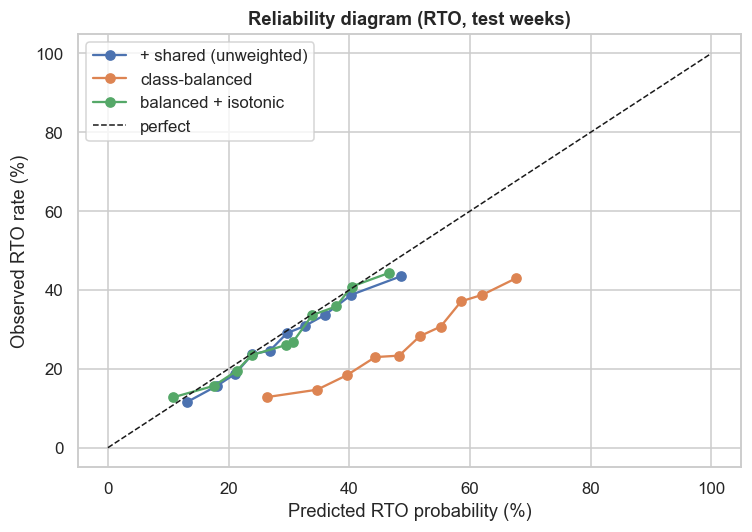

,AUC,Brier,ECE,mean pred − obs,calibration slope
model,,,,,
fraud: task-only,0.7425,0.0019,0.0007,0.0005,0.4705
fraud: + shared rep,0.6616,0.0022,0.0015,0.0009,0.3924
routing: task-only,0.6645,0.1098,0.0039,-0.0001,1.0447
routing: + shared rep,0.6624,0.1099,0.0070,-0.0002,1.1019
RTO (COD): task-only,0.6237,0.1906,0.0187,0.0179,0.9317
RTO (COD): + shared rep,0.6409,0.1882,0.0201,0.0201,0.9834
"RTO: + shared, class-balanced weights",0.6438,0.2360,0.2182,0.2182,1.0382
"RTO: + shared, balanced + isotonic (wk 9–10)",0.6431,0.1876,0.0175,0.0128,0.9789


In [11]:
def ece(y, p, b=10):
    q = pd.qcut(p, b, labels=False, duplicates="drop"); g = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q")
    return float((g.size() / len(p) * (g.p.mean() - g.y.mean()).abs()).sum())
def cal_slope(y, p):
    lp = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    return sm.Logit(y, sm.add_constant(lp)).fit(disp=0).params[1]
def calrow(name, y, p): return (name, roc_auc_score(y, p), brier_score_loss(y, p), ece(y, p), p.mean() - y.mean(), cal_slope(y, p))
crow = []
for t in TASKS:
    o_ = OUT[t]; crow += [calrow(f"{t}: task-only", o_["y"], o_["p0"]), calrow(f"{t}: + shared rep", o_["y"], o_["p1"])]
s = TASKS["RTO (COD)"]; o_ = OUT["RTO (COD)"]
m_w = fit_head(s["tab"], True, o_["tr"], df.loc[o_["tr"], "rto"], class_weight="balanced")
pw_te = m_w.predict_proba(design(s["tab"], True, o_["te"]))[:, 1]; pw_cal = m_w.predict_proba(design(s["tab"], True, o_["cal"]))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4).fit(pw_cal, df.loc[o_["cal"], "rto"]); pw_iso = iso.predict(pw_te)
crow += [calrow("RTO: + shared, class-balanced weights", o_["y"], pw_te), calrow("RTO: + shared, balanced + isotonic (wk 9–10)", o_["y"], pw_iso)]
calt = pd.DataFrame(crow, columns=["model", "AUC", "Brier", "ECE", "mean pred − obs", "calibration slope"]).set_index("model")
fig, ax = plt.subplots(figsize=(7, 5))
for nm, p_ in (("+ shared (unweighted)", o_["p1"]), ("class-balanced", pw_te), ("balanced + isotonic", pw_iso)):
    q = pd.qcut(p_, 10, labels=False, duplicates="drop"); g = pd.DataFrame({"y": o_["y"], "p": p_, "q": q}).groupby("q").mean()
    ax.plot(g.p * 100, g.y * 100, "o-", label=nm)
ax.plot([0, 100], [0, 100], "k--", lw=1, label="perfect"); ax.set_xlabel("Predicted RTO probability (%)"); ax.set_ylabel("Observed RTO rate (%)")
ax.set_title("Reliability diagram (RTO, test weeks)"); ax.legend(); plt.tight_layout(); plt.show()
calt.round(4)

**Takeaway:** - **Calibration is fine for the unweighted heads:** routing ECE 0.004 (slope 1.04), RTO ECE ≈ 0.02 (slope 0.93–0.98).
- **Fraud is over-confident:** slope 0.47 means scores are too extreme, even though the mean is close (+0.05 pp). Its probabilities should not be multiplied by ₹ without recalibration.
- **The demonstration:** training the RTO head with **class-balanced weights** leaves the AUC unchanged (0.644 vs 0.641) but **inflates every probability by 22 points** (mean predicted − observed = +0.218; ECE 0.218; the reliability curve sits far right of the diagonal).
- **Isotonic recalibration** on weeks 9–10 restores calibration (ECE 0.018, slope 0.98) **without changing the ranking** (AUC 0.643).
- **Lesson:** ranking and calibration are different properties. **A model can pass an AUC review and still mis-price every decision.** Check both, as the blog does.

### 7.6 Slices: per payment flow (the blog's "inspect the slices")

A model that wins on average can lose on a slice. We compute the AUC difference (with vs without the representation) **per payment method** for fraud and routing, plus RTO by shopper history depth, with DeLong p-values and **Benjamini–Hochberg** across all slices (an exploratory screen, so we control the false-discovery rate).

In [12]:
sl = []
def add_slice(task, name, mask):
    o_ = OUT[task]; y_ = o_["y"][mask]
    if y_.sum() < 15 or (1 - y_).sum() < 15: return
    a_, c_ = delong(y_, np.vstack([o_["p0"][mask], o_["p1"][mask]])); se_ = np.sqrt(c_[0, 0] + c_[1, 1] - 2 * c_[0, 1])
    sl.append((task, name, int(mask.sum()), int(y_.sum()), a_[0], a_[1], a_[1] - a_[0], 2 * stats.norm.sf(abs((a_[1] - a_[0]) / se_))))
for t in ("fraud", "routing"):
    meth = df.loc[OUT[t]["te"], "method"].values
    for m_ in ["card", "upi", "netbanking", "wallet"]: add_slice(t, f"method = {m_}", meth == m_)
hist = pd.cut(df.loc[OUT["RTO (COD)"]["te"], "cust_nprior"].values, [-1, 4, 12, 10_000], labels=["0–4 prior payments", "5–12", "13+"])
for h_ in hist.categories: add_slice("RTO (COD)", f"history {h_}", np.asarray(hist == h_))
sl = pd.DataFrame(sl, columns=["task", "slice", "n", "positives", "AUC task-only", "AUC + shared", "Δ AUC", "p"])
sl["q_BH"] = multipletests(sl.p, method="fdr_bh")[1]; sl.round(4)

,task,slice,n,positives,AUC task-only,AUC + shared,Δ AUC,p,q_BH
0,fraud,method = card,12657,49,0.7841,0.6463,-0.1378,0.0829,0.2721
1,fraud,method = upi,22111,38,0.6764,0.6468,-0.0296,0.4000,0.4895
2,routing,method = card,12657,11031,0.6464,0.6429,-0.0034,0.2576,0.3864
3,routing,method = upi,22111,18708,0.6516,0.6501,-0.0015,0.4351,0.4895
4,routing,method = netbanking,6775,5653,0.6576,0.6535,-0.0042,0.2483,0.3864
5,routing,method = wallet,9856,9167,0.5265,0.5332,0.0067,0.6070,0.6070
6,RTO (COD),history 0–4 prior payments,938,246,0.6031,0.6306,0.0275,0.1209,0.2721
7,RTO (COD),history 5–12,2381,651,0.6267,0.6415,0.0148,0.1122,0.2721
8,RTO (COD),history 13+,2123,573,0.6302,0.6468,0.0166,0.0816,0.2721


**Observation:** no slice reaches significance after BH (all q ≥ 0.27), so **there is no hidden slice where the shared representation shines for routing or fraud**.
- **Fraud on card payments** shows the largest *loss* (AUC 0.784 → 0.646, q = 0.27). That is consistent with the overall fraud result, but too few frauds per slice (38–49) to be sure.
- **RTO** gains are similar across shopper-history depths (+0.015 to +0.028). The representation helps new and established shoppers alike rather than only the data-poor.
- **Routing:** no change in any method slice.

The slice view did its job: **it found no slice-level surprise that the average hides**.

### 7.7 Checkout ordering: does the representation help show each shopper their preferred method first?

Target: the method the shopper chose (5 classes). The **metric is top-1 accuracy**: the share of shoppers who would see their chosen method in first position (the documented "40% more shoppers seeing preferred UPI app" is this kind of metric, at app level). Baselines: (a) always show UPI (most popular); (b) the shopper's last-used method. Models: a multi-class head on context (category, amount, hour, last method, history length) with vs without the shared vector. **McNemar** on the same test shoppers; Wilson CIs.

In [13]:
tabc = ["merchant_cat_c", "hour", "log_amt", "cust_last_method_c", "cust_nprior"]; cmc = [True, False, False, True, False]
tr = df.index[TR]; te = df.index[TE]; yc_te = df.loc[te, "method"].values
mc0 = HGB(max_iter=200, learning_rate=0.08, random_state=SEED, categorical_features=cmc).fit(df.loc[tr, tabc].values, df.loc[tr, "method"])
mc1 = HGB(max_iter=200, learning_rate=0.08, random_state=SEED, categorical_features=cmc + [False] * 32).fit(np.hstack([df.loc[tr, tabc].values, EMB[tr]]), df.loc[tr, "method"])
pred0 = mc0.predict(df.loc[te, tabc].values); pred1 = mc1.predict(np.hstack([df.loc[te, tabc].values, EMB[te]]))
last = df.loc[te, "cust_last_method"].values
acc = {"always UPI": yc_te == "upi", "last-used method": np.where(last == "none", "upi", last) == yc_te, "model: task-only": pred0 == yc_te, "model: + shared rep": pred1 == yc_te}
ck = pd.DataFrame({k: {"top-1 accuracy": v.mean(), "CI low": proportion_confint(v.sum(), len(v), method="wilson")[0], "CI high": proportion_confint(v.sum(), len(v), method="wilson")[1]} for k, v in acc.items()}).T
a, b = acc["model: task-only"], acc["model: + shared rep"]
mt = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=False, correction=True)
print(f"McNemar (+shared vs task-only): only task-only right {int((a & ~b).sum()):,}, only +shared right {int((~a & b).sum()):,}, chi2 = {mt.statistic:.1f}, p = {mt.pvalue:.2g}")
print(f"Relative gain in shoppers seeing their chosen method first vs always-UPI: {b.mean() / acc['always UPI'].mean() - 1:+.0%}; vs task-only model: {b.mean() / a.mean() - 1:+.0%}")
CK_ACC = acc; ck.round(4)

McNemar (+shared vs task-only): only task-only right 3,886, only +shared right 6,035, chi2 = 465.1, p = 3.8e-103
Relative gain in shoppers seeing their chosen method first vs always-UPI: +15%; vs task-only model: +9%


,top-1 accuracy,CI low,CI high
always UPI,0.3890,0.3850,0.3930
last-used method,0.3772,0.3732,0.3812
model: task-only,0.4111,0.4070,0.4151
model: + shared rep,0.4489,0.4448,0.4530


**Observation:** - "Always show UPI" puts the chosen method first for **38.9%** of shoppers. "Last-used method" scores 37.7%: shoppers switch methods often, so a naive habit rule loses to plain popularity.
- The task model reaches **41.1%**. Adding the shared representation reaches **44.9%** (CI 44.5–45.3%). 6,035 shoppers are right only with +shared vs 3,886 only with task-only (McNemar χ² = 465, **p ≈ 4e-103**).
- **Relative gains:** +9% vs the task model and **+15% vs always-UPI**. That is the same kind of metric as Razorpay's "40% more shoppers seeing preferred UPI app", measured here at method level rather than app level.
- **(f) Business meaning:** method preference is a *who-is-this-shopper* question, exactly what an unlabelled representation of shoppers, merchants and places captures. **This is the strongest use case for the shared representation.**

### 7.8 Label efficiency: the main promise of pre-training

Foundation models are supposed to shine when a task has **few labels** (a new product or a new merchant), because the representation is learned from unlabelled data. We retrain the RTO and checkout heads on 5%, 20% and 100% of the training labels (RTO: 3 random draws each; checkout: 1) and measure out-of-time performance.

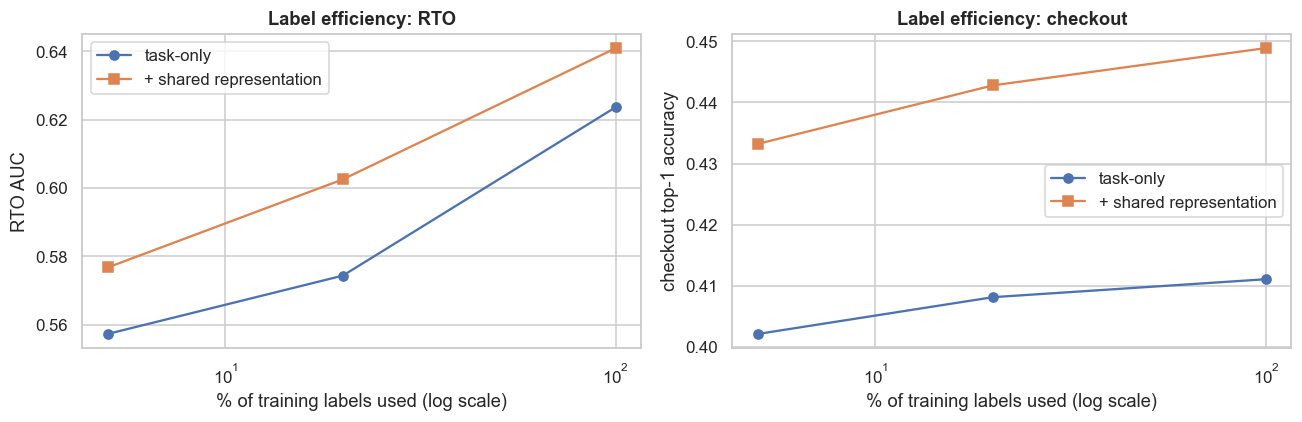

task-only  + shared rep   gain
metric                  share of labels                                
RTO AUC                 0.0500              0.5573        0.5767 0.0194
                        0.2000              0.5744        0.6025 0.0282
                        1.0000              0.6237        0.6409 0.0173
checkout top-1 accuracy 0.0500              0.4021        0.4332 0.0311
                        0.2000              0.4081        0.4428 0.0346
                        1.0000              0.4111        0.4489 0.0378

In [14]:
le = []
s = TASKS["RTO (COD)"]; o_ = OUT["RTO (COD)"]
for frac in (0.05, 0.2, 1.0):
    for rep in range(3 if frac < 1 else 1):
        sub = np.sort(RNG.choice(o_["tr"], int(frac * len(o_["tr"])), replace=False))
        for w_ in (False, True):
            m_ = fit_head(s["tab"], w_, sub, df.loc[sub, "rto"]); le.append(("RTO AUC", frac, w_, roc_auc_score(o_["y"], m_.predict_proba(design(s["tab"], w_, o_["te"]))[:, 1])))
for frac in (0.05, 0.2, 1.0):
    sub = np.sort(RNG.choice(tr, int(frac * len(tr)), replace=False))
    for w_ in (False, True):
        Xs = np.hstack([df.loc[sub, tabc].values, EMB[sub]]) if w_ else df.loc[sub, tabc].values; Xt = np.hstack([df.loc[te, tabc].values, EMB[te]]) if w_ else df.loc[te, tabc].values
        m_ = HGB(max_iter=200, learning_rate=0.08, random_state=SEED, categorical_features=cmc + ([False] * 32 if w_ else [])).fit(Xs, df.loc[sub, "method"])
        le.append(("checkout top-1 accuracy", frac, w_, (m_.predict(Xt) == yc_te).mean()))
le = pd.DataFrame(le, columns=["metric", "share of labels", "shared rep", "score"]).groupby(["metric", "share of labels", "shared rep"]).score.mean().unstack()
le.columns = ["task-only", "+ shared rep"]; le["gain"] = le["+ shared rep"] - le["task-only"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (mname, g) in zip(axes, le.groupby(level=0)):
    xs_ = g.index.get_level_values(1) * 100
    ax.plot(xs_, g["task-only"], "o-", label="task-only"); ax.plot(xs_, g["+ shared rep"], "s-", label="+ shared representation")
    ax.set_xscale("log"); ax.set_xlabel("% of training labels used (log scale)"); ax.set_ylabel(mname); ax.set_title(f"Label efficiency: {mname.split()[0]}"); ax.legend()
plt.tight_layout(); plt.show()
le.round(4)

**Takeaway:** the promise of pre-training is clearest for **checkout**: the shared representation adds **+3.1 pp with 5% of labels** and +3.8 pp with all of them, and the +shared model trained on 5% of the labels (43.3%) **beats the task-only model trained on all labels** (41.1%). For **RTO**, the gain is +0.019 to +0.028 AUC at every label budget. With 5% of labels, the +shared model (0.577) is as good as a task-only model with about 4× more labels. **Business meaning:** for a new product or merchant with few labels (a new COD category, a new checkout surface), the shared representation is a head start. For routing and fraud it is not a substitute for the right features.

## 8. ML Section — what we built, and what Vulcan does differently

| | Our notebook | Razorpay Vulcan (documented) |
|---|---|---|
| Input | 7 hashed "who/where" fields | ~3,000 signals per payment, hashed tokens |
| Pre-training | IDF-weighted hashed co-occurrence → truncated SVD (linear, 32 dims) | Masked-field prediction with a **Set Transformer** (non-linear, attention between fields) |
| Pooling | Sum of field vectors (order-free) | Attention pooling (order-free) |
| Heads | Gradient boosting per task, same features ± shared vector | Task heads; routing adds a recent-context encoder, fusion and calibration |
| Scale | 0.34 M payments, CPU, minutes | 4 B payments, GPU cluster |

Our linear stand-in captures the **mechanism** (unlabelled co-occurrence → reusable vectors) and lets us test the **evaluation discipline**. It cannot reproduce non-linear field interactions learned by attention, so the effect sizes here are a *lower bound* on what a full model might add for the tasks where the representation helps. They do not show it would help the tasks where it did not.

## 9. Business Translation — ₹ impact per task

In [15]:
# --- routing: choose the gateway with the highest predicted success ---
s = TASKS["routing"]; o_ = OUT["routing"]; te = o_["te"]; m0, m1 = MODELS["routing"]
truth = df.loc[te, ["_p_G1", "_p_G2", "_p_G3"]].values; logged = df.loc[te, "gateway"].values; yy = o_["y"]
def gw_scores(m, w_):
    out = []
    for g in ["G1", "G2", "G3"]:
        X_ = design(s["tab"], w_, te); X_[:, s["tab"].index("gateway_c")] = CODES["gateway"].index(g); out.append(m.predict_proba(X_)[:, 1])
    return np.vstack(out).T
static = df.loc[o_["tr"]].groupby(["method", "gateway"]).route_success.mean().unstack().idxmax(1)
choice = {"current (random 1/3 each)": None, "static best gateway per method": pd.Series(df.loc[te, "method"]).map(static).str[1].astype(int).values - 1,
          "model: task-only": gw_scores(m0, False).argmax(1), "model: + shared rep": gw_scores(m1, True).argmax(1), "oracle (true best)": truth.argmax(1)}
rr = []
for k, c in choice.items():
    if c is None: sr_true = truth.mean(); ipw = yy.mean(); se_ipw = yy.std() / np.sqrt(len(yy))
    else:
        sr_true = truth[np.arange(len(c)), c].mean(); match = (np.array(["G1", "G2", "G3"])[c] == logged)
        v = match * yy * 3; ipw = v.mean(); se_ipw = v.std() / np.sqrt(len(v))
    rr.append((k, sr_true, ipw, ipw - 1.96 * se_ipw, ipw + 1.96 * se_ipw))
route = pd.DataFrame(rr, columns=["routing policy", "true expected SR (digital twin)", "IPW estimate from logs", "IPW CI low", "IPW CI high"]).set_index("routing policy")
c0, c1 = choice["model: task-only"], choice["model: + shared rep"]
dlt = truth[np.arange(len(c1)), c1] - truth[np.arange(len(c0)), c0]
bsd = [dlt[RNG.integers(0, len(dlt), len(dlt))].mean() * 100 for _ in range(2000)]
print(f"Routing SR, + shared vs task-only: {dlt.mean() * 100:+.3f} pp (95% bootstrap CI {np.percentile(bsd, 2.5):+.3f} to {np.percentile(bsd, 97.5):+.3f})")
route.round(4)

Routing SR, + shared vs task-only: -0.101 pp (95% bootstrap CI -0.108 to -0.094)


,true expected SR (digital twin),IPW estimate from logs,IPW CI low,IPW CI high
routing policy,,,,
current (random 1/3 each),0.8663,0.8669,0.8640,0.8699
static best gateway per method,0.8828,0.8686,0.8569,0.8804
model: task-only,0.9171,0.9205,0.9085,0.9325
model: + shared rep,0.9161,0.9170,0.9051,0.9290
oracle (true best),0.9182,0.9239,0.9119,0.9359


In [16]:
PAY_M = 1e7                                                  # scale: 1 crore payments per month (assumption, D-3b-07)
avg_t = df.amount_inr.mean(); online_share = (df.method != "cod").mean(); cod_share = (df.method == "cod").mean()
gain_route = (route.loc["model: task-only", "true expected SR (digital twin)"] - route.loc["current (random 1/3 each)", "true expected SR (digital twin)"])
o = OUT["fraud"]; fraud_rate = o["y"].mean(); fraud_ticket = df.loc[o["te"]][o["y"] == 1].amount_inr.mean()
r0, r1 = bud.loc["0.50%", "recall task-only"], bud.loc["0.50%", "recall + shared"]
o = OUT["RTO (COD)"]; k = int(0.10 * len(o["y"]))
prec0 = o["y"][np.argsort(-o["p0"])[:k]].mean(); prec1 = o["y"][np.argsort(-o["p1"])[:k]].mean(); RTO_COST, CONVERT = 180, 0.5
ck_gain = CK_ACC["model: + shared rep"].mean() - CK_ACC["model: task-only"].mean(); LIFT_IF_FIRST = 0.01
money = pd.DataFrame([
    ("Routing: task model vs current random split", f"SR {gain_route * 100:+.2f} pp", gain_route * PAY_M * online_share * avg_t / 1e7, "GMV recovered (₹ crore/month)"),
    ("Routing: + shared rep vs task model", f"SR {dlt.mean() * 100:+.3f} pp", dlt.mean() * PAY_M * online_share * avg_t / 1e7, "GMV (₹ crore/month)"),
    ("Fraud at 0.5% alerts: + shared vs task model", f"recall {(r1 - r0) * 100:+.1f} pp", (r1 - r0) * fraud_rate * PAY_M * fraud_ticket / 1e7, "fraud loss avoided (₹ crore/month)"),
    ("RTO: flag top 10% COD for prepaid nudge, + shared vs task", f"precision {prec0:.1%} → {prec1:.1%}", (prec1 - prec0) * 0.10 * cod_share * PAY_M * CONVERT * RTO_COST / 1e7, "RTO cost avoided (₹ crore/month)"),
    ("Checkout: + shared vs task model", f"top-1 {ck_gain * 100:+.1f} pp", ck_gain * LIFT_IF_FIRST * PAY_M * avg_t / 1e7, "GMV (₹ crore/month, if 'first' lifts completion 1 pp)"),
], columns=["lever", "effect (test weeks)", "₹ crore / month", "what the ₹ means"]).set_index("lever")
print(f"Per 1 crore payments/month: avg ticket ₹{avg_t:,.0f}; fraud rate {fraud_rate:.2%}, avg fraud ticket ₹{fraud_ticket:,.0f}; COD share {cod_share:.1%}")
money.round(3)

Per 1 crore payments/month: avg ticket ₹1,118; fraud rate 0.21%, avg fraud ticket ₹3,145; COD share 9.6%


,effect (test weeks),₹ crore / month,what the ₹ means
lever,,,
Routing: task model vs current random split,SR +5.08 pp,51.3270,GMV recovered (₹ crore/month)
Routing: + shared rep vs task model,SR -0.101 pp,-1.0200,GMV (₹ crore/month)
Fraud at 0.5% alerts: + shared vs task model,recall -7.6 pp,-0.4980,fraud loss avoided (₹ crore/month)
"RTO: flag top 10% COD for prepaid nudge, + shared vs task",precision 42.6% → 43.6%,0.0080,RTO cost avoided (₹ crore/month)
Checkout: + shared vs task model,top-1 +3.8 pp,0.4230,"GMV (₹ crore/month, if 'first' lifts completio..."


**Takeaway (business reading):** - **Routing (the biggest lever):** a task model choosing the gateway with the highest predicted success lifts **true expected SR from 86.6% to 91.7% (+5.1 pp)**, within 0.1 pp of the oracle (91.8%). The IPW estimate from logged random traffic agrees (92.1%, CI 90.9–93.3%), which shows a real team could have measured this *before* deployment. A static "best gateway per method" rule gets only 88.3%. **Per 1 crore payments a month (₹1,118 average), ≈ ₹51 crore of extra GMV processed.** The shared representation adds nothing here (−0.1 pp).
  - The documented "8–10% SR improvement" is larger than our +5.1 pp. Our simulated bank × gateway differences are smaller than real-world variation, so treat both as order-of-magnitude.
- **Fraud:** at a 0.5% alert budget, the shared representation catches 7.6 pp fewer frauds ≈ **−₹0.5 crore/month of fraud loss avoided**. A cost, not a benefit.
- **RTO:** flagging the top 10% riskiest COD orders for a prepaid nudge (50% conversion, ₹180 per RTO) gains only ≈ ₹0.01 crore/month from the representation. Statistically real, commercially small.
- **Checkout:** +3.8 pp of shoppers seeing their method first. *If* that lifts completion by 1 pp for them (an assumption to test), ≈ **₹0.4 crore/month** of GMV.
- **Reading:** almost all the ₹ is in **having good task models** (routing). The shared representation is a modest bonus for shopper-centric tasks and a loss for fraud.

## 10. Recommendation and Decision

**Decision against the pre-registered rule (per task):**

| Task | Business metric improved (Holm)? | Calibrated? | Decision |
|---|---|---|---|
| Checkout ordering | ✅ +3.8 pp top-1 (p ≈ 4e-103) | n/a (ranking) | **Adopt** the shared representation |
| RTO (COD) | ✅ AUC +0.017 (p = 0.015), small ₹ | ✅ | Optional: adopt where data is thin (new categories) |
| Routing | ❌ −0.1 pp | ✅ | Keep the task model, which is itself worth +5.1 pp vs random |
| Fraud | ❌ worse at fixed alerts (−7.6 pp; p = 0.06 at 0.5%, 0.007 at 1%) | ❌ over-confident | **Do not adopt.** Keep the task model |

**I recommend:**
1. **Treat a foundation representation as a feature, not a replacement.** Each head must beat its task-only model on an **out-of-time, business-metric** test before switching.
2. **Ship model-based routing now.** It is the largest ₹ lever, and an IPW estimate from randomised logs already supports it. Keep 5–10% randomised routing for continuous evaluation.
3. **Fraud:** re-test the representation with ≥ 8 weeks of matured labels, a lower-capacity head (logistic, or only a few embedding dimensions), and frequent embedding refreshes so new devices get vectors. Until then, keep the task model with velocity counters.
4. **Standards for every model review:** out-of-time split with as-of labels, recall at the real alert budget, calibration (ECE and slope) next to AUC, slice tables with FDR control, and a power statement.

**KPIs:** routing SR vs randomised holdout; fraud recall and precision at a fixed alert volume (matured labels); RTO rate among nudged COD orders; share of shoppers completing with the first-shown method; calibration error per head; embedding-refresh coverage (share of payments whose tokens have vectors).

## 11. Risks, Limitations and Next Steps

- **Synthetic data and a linear stand-in:** the hidden segment structure was *designed* to be learnable from co-occurrence, which favours the representation for segment-driven tasks (checkout, RTO). Fraud rings and bank × gateway effects were not designed that way. Real data will differ: re-run this exact evaluation on real traffic before any claim.
- **Fraud labels:** our test frauds are few (≈ 120 in 2 weeks), so fraud comparisons have wide CIs (power check in 7.3). A real evaluation needs ≥ 6–8 weeks of matured labels, i.e., an evaluation lag of about 2 months.
- **Embedding refresh:** tokens unseen at pre-training (new shoppers, new fraud devices) get no vector. The representation must be refreshed frequently, and heads must not depend on it for brand-new entities.
- **Privacy:** hashed identifiers are still personal data under the DPDP Act 2023 when re-identifiable. Purpose limitation applies when a fraud-trained representation is reused for marketing-like tasks (checkout ordering).
- **Governance:** a shared representation couples four products. A bad refresh can break all four at once, so version it, shadow-test each refresh on all heads, and keep the task-only models as a fallback.

## 12. Appendix

| Quantity | Formula |
|---|---|
| IDF weight | idf(t) = ln((1 + N)/(1 + df(t))) + 1 |
| Payment embedding | e(payment) = Σ_fields  onehot(token) · idf · V  (V = top-32 right singular vectors) |
| DeLong test | z = (AUC₁ − AUC₂)/√(Var₁ + Var₂ − 2Cov), placement-value covariance |
| Recall at budget b | frauds in the top b·N scores / all frauds |
| McNemar | χ² = (|n₁₀ − n₀₁| − 1)²/(n₁₀ + n₀₁), or exact binomial on discordant pairs |
| ECE | Σ_bins (n_b/N) · |mean p_b − mean y_b| |
| Calibration slope | β in logit P(y = 1) = α + β·logit(p̂) |
| IPW policy value | V̂(π) = mean( 1{π(x) = logged gateway} · y / (1/3) ) |

| Term | Meaning |
|---|---|
| Foundation model / representation | A general-purpose numeric description learned from unlabelled data, reused by many tasks |
| Self-supervised / masked-field prediction | Learning by hiding part of the input and predicting it, so no labels are needed |
| Set Transformer | A neural network for unordered sets of fields |
| Head | The small task-specific model on top of the representation |
| Out-of-time test | Train on the past, test on later weeks, as in production |
| As-of labels | Labels as known on the training date, not with hindsight |
| Alert budget | The number of fraud alerts analysts can review |
| RTO | Return to origin: a COD parcel refused at the door |
| Calibration | Whether predicted probabilities match observed rates |